# 2

### Nota: 8.3

En este proyecto de clasificación binaria, desarrollarás un sistema que prediga si una persona sobrevivió o no al hundimiento del Titanic, utilizando el conjunto de datos proporcionado (dataset.csv). Implementarás y compararás cinco modelos de clasificación supervisada: Regresión Logística, K-Nearest Neighbors (KNN), Support Vector Classifier (SVC), Árbol de Decisión, y Random Forest. Utilizarás Python y las librerías de scikit-learn para llevar a cabo el preprocesamiento de datos, entrenar los modelos y evaluar su rendimiento. Este reto pondrá a prueba tus conocimientos en machine learning supervisado, aplicando diferentes enfoques de clasificación a un problema real con el objetivo de optimizar las predicciones.

In [134]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as sk

work_dir = "../media/1_lab4/2/"
file_dir = "dataset.csv"
path = work_dir + file_dir
seed = 112211

Cargamos los datos y vemos las primeras columnas.

In [135]:
df = pd.read_csv(path)
df_original = df.copy()
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [136]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


Tenemos 12 columnas.
- PassengerId: ID de cada pasajero (lo convertimos en el índice) (int)
- Survived: Variable a predecir con valores únicos (0 -> no sobrevive, 1 -> sobrevive) (int)
- Pclass: Clase de pasajero. Valores posibles -> 1, 2, 3 (int)
- Name: Nombre del pasajero (str)
- Sex: Sexo del pasajero (str)
- Age: Edad del pasajero (str)
- SibSp: (int)
- Parch: (int)
- Ticket: Etiqueta del ticket (str)
- Fare: (float)
- Cabin: Letra y número de cabina (str)
- Embarked: Tipo de embarque -> S, C, Q (str)

Vemos y tratamos los valores nulos.

In [137]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Hay distintos tipos de categorías con valores nulos, veamos que hacer con cada uno.

- Age (177) -> Es una variable interesante para usar, vamos a usar la mediana para rellenar valores nulos
- Cabin (687) -> Es una cantidad importante de valores nulos, y el dataset es pequeño. Categoría que a priori no parece interesante, ni de ayuda, por lo que se elimina
- Embarked (2) -> Solo son dos valores, podríamos eliminarlos, pero vamos a aplicar la moda.

In [138]:
df = df.set_index("PassengerId")
df = df.fillna({"Age": df.Age.median(), "Embarked": df.Embarked.mode()[0]})
df = df.drop(columns = "Cabin")

In [139]:
df.isna().sum()

Survived    0
Pclass      0
Name        0
Sex         0
Age         0
SibSp       0
Parch       0
Ticket      0
Fare        0
Embarked    0
dtype: int64

Claramente el nombre no va a ser un factor decisivo en la predicción, y tampoco el ticket (además, no sería para nada práctico codificar estas variables), así que las eliminamos.

In [140]:
df = df.drop(columns = ["Name", "Ticket"])

In [141]:
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
PassengerId,,,,,,,,
1,0,3,male,22.0,1,0,7.2500,S
2,1,1,female,38.0,1,0,71.2833,C
3,1,3,female,26.0,0,0,7.9250,S
4,1,1,female,35.0,1,0,53.1000,S
5,0,3,male,35.0,0,0,8.0500,S


Vamos a aplicar One Hot Encoding mediante el método get_dummies de pandas para convertir las variables categóricas a numéricas. Concretamente Sex y Embarked

In [142]:
df = pd.get_dummies(df, prefix = ["Sex", "Embarked"]).astype(int)

In [143]:
df.head()

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
PassengerId,,,,,,,,,,,
1,0,3,22,1,0,7,0,1,0,0,1
2,1,1,38,1,0,71,1,0,1,0,0
3,1,3,26,0,0,7,1,0,0,0,1
4,1,1,35,1,0,53,1,0,0,0,1
5,0,3,35,0,0,8,0,1,0,0,1


Por último modificamos las variables numéricas, principalmente Age y Fare, que son las que más variabilidad tienen.

In [144]:
df[["Age", "Fare"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,891.0,29.345679,13.028212,0.0,22.0,28.0,35.0,80.0
Fare,891.0,31.785634,49.703730,0.0,7.0,14.0,31.0,512.0


Parece que Fare es asimétrica, veámoslo con un histplot

Text(0.5, 1.0, 'Fare')

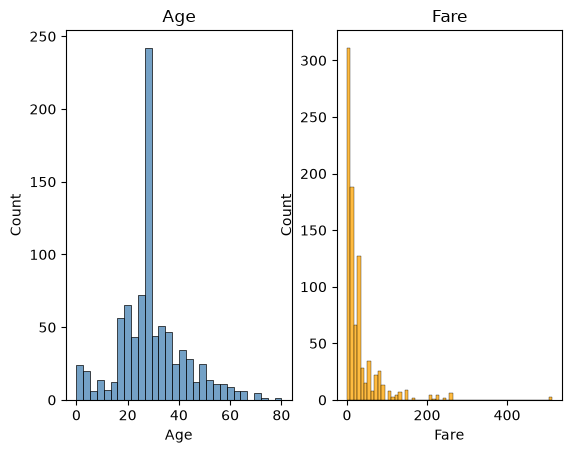

In [145]:
fig, ax = plt.subplots(nrows = 1, ncols = 2)

sns.histplot(data = df, x = "Age", ax = ax[0], color = "steelblue")
sns.histplot(data = df, x = "Fare", ax = ax[1], color = "orange")
ax[0].set_title("Age")
ax[1].set_title("Fare")

En efecto Age es más simétrica (Normal), y Fare tiene cola larga hacia la derecha, veamos si hay outliers.

<Axes: ylabel='Fare'>

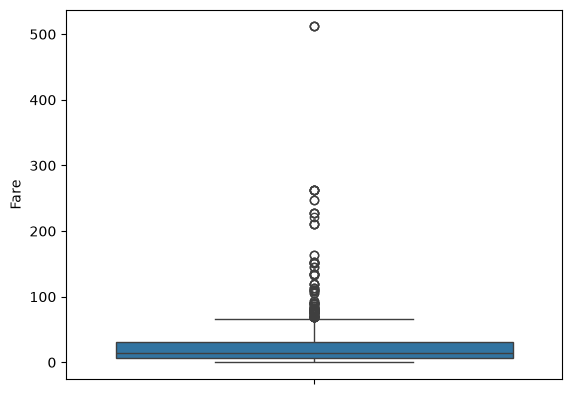

In [146]:
sns.boxplot(data = df, y = "Fare")

En un estudio más profundo, habría que estudiar el rango IQR y estudiar cómo tratar estos valores, nosotros lo dejaremos así. Vamos entonces a normalizar la variable Fare, y a estandarizar la edad.

In [147]:
standard = lambda x: (x - x.mean()) / x.std()
normalize = lambda x: (x - x.min()) / (x.max() - x.min())

df["Age"] = standard(df.Age)
df["Fare"] = standard(df.Fare)

In [148]:
df[["Age", "Fare"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,891.0,-1.116453e-16,1.0,-2.252472,-0.563829,-0.103290,0.434006,3.888049
Fare,891.0,4.984166e-17,1.0,-0.639502,-0.498667,-0.357833,-0.015806,9.661536


Ya que tenemos el dataset preparado para el modelo, vamos a dividir en set de entrenamiento y de test.

In [149]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(df_original.drop(columns = "Survived"), df_original["Survived"], test_size = 0.2, random_state = seed)

Vamos a definir el ColumnTransformer preprocessor, cuya entrada es el DataFrame original, y devuelve el DataFrame procesado, luego definimos los modelos que queremos usar para el entrenamiento.

In [150]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        # Age y Fare: mediana para nulos y estandarización
        ("num_std", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), ["Age", "Fare"]),

        # Sex: sin nulos, solo One Hot Encoding
        ("sex", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Sex"]),

        # Embarked: moda para nulos y One Hot Encoding
        ("embarked", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), ["Embarked"]),

        # Estas columnas pasan sin cambios
        ("num_pass", "passthrough", ["Pclass", "SibSp", "Parch"]),
    ],
    remainder="drop",   # elimina Cabin, Name y Ticket
).set_output(transform="pandas")

Cargamos modelos.

In [151]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = [LogisticRegression(), KNeighborsClassifier(), SVC(), DecisionTreeClassifier(), RandomForestClassifier()]

Construimos el pipeline para cada modelo.

In [152]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve, roc_auc_score, RocCurveDisplay

t_models = {}
acc = {}
cm = {}
report = {}
roc = {}

for model in models:
    print(f"Entrenando: {model}")
    clf = sk.pipeline.Pipeline(steps = [("preprocessor", preprocessor), ("classifier", model)])
    trained_model = clf.fit(X_train, y_train)
    t_models[model] = trained_model
    preds = trained_model.predict(X_test)
    acc[model] = accuracy_score(y_test, preds)
    print(f"Listo! Precisión: {acc[model]}\n")
    cm[model] = confusion_matrix(y_test, preds)
    report[model] = classification_report(y_test, preds, zero_division = 1)
    print(report[model])
    roc[model] = roc_auc_score(y_test, preds)

Entrenando: LogisticRegression()
Listo! Precisión: 0.770949720670391

              precision    recall  f1-score   support

           0       0.80      0.85      0.82       111
           1       0.72      0.65      0.68        68

    accuracy                           0.77       179
   macro avg       0.76      0.75      0.75       179
weighted avg       0.77      0.77      0.77       179

Entrenando: KNeighborsClassifier()
Listo! Precisión: 0.7877094972067039

              precision    recall  f1-score   support

           0       0.80      0.87      0.84       111
           1       0.76      0.65      0.70        68

    accuracy                           0.79       179
   macro avg       0.78      0.76      0.77       179
weighted avg       0.79      0.79      0.78       179

Entrenando: SVC()
Listo! Precisión: 0.8268156424581006

              precision    recall  f1-score   support

           0       0.82      0.92      0.87       111
           1       0.84      0.68     

En las siguientes celdas vamos a graficar las matrices de confusión, y las curvas ROC

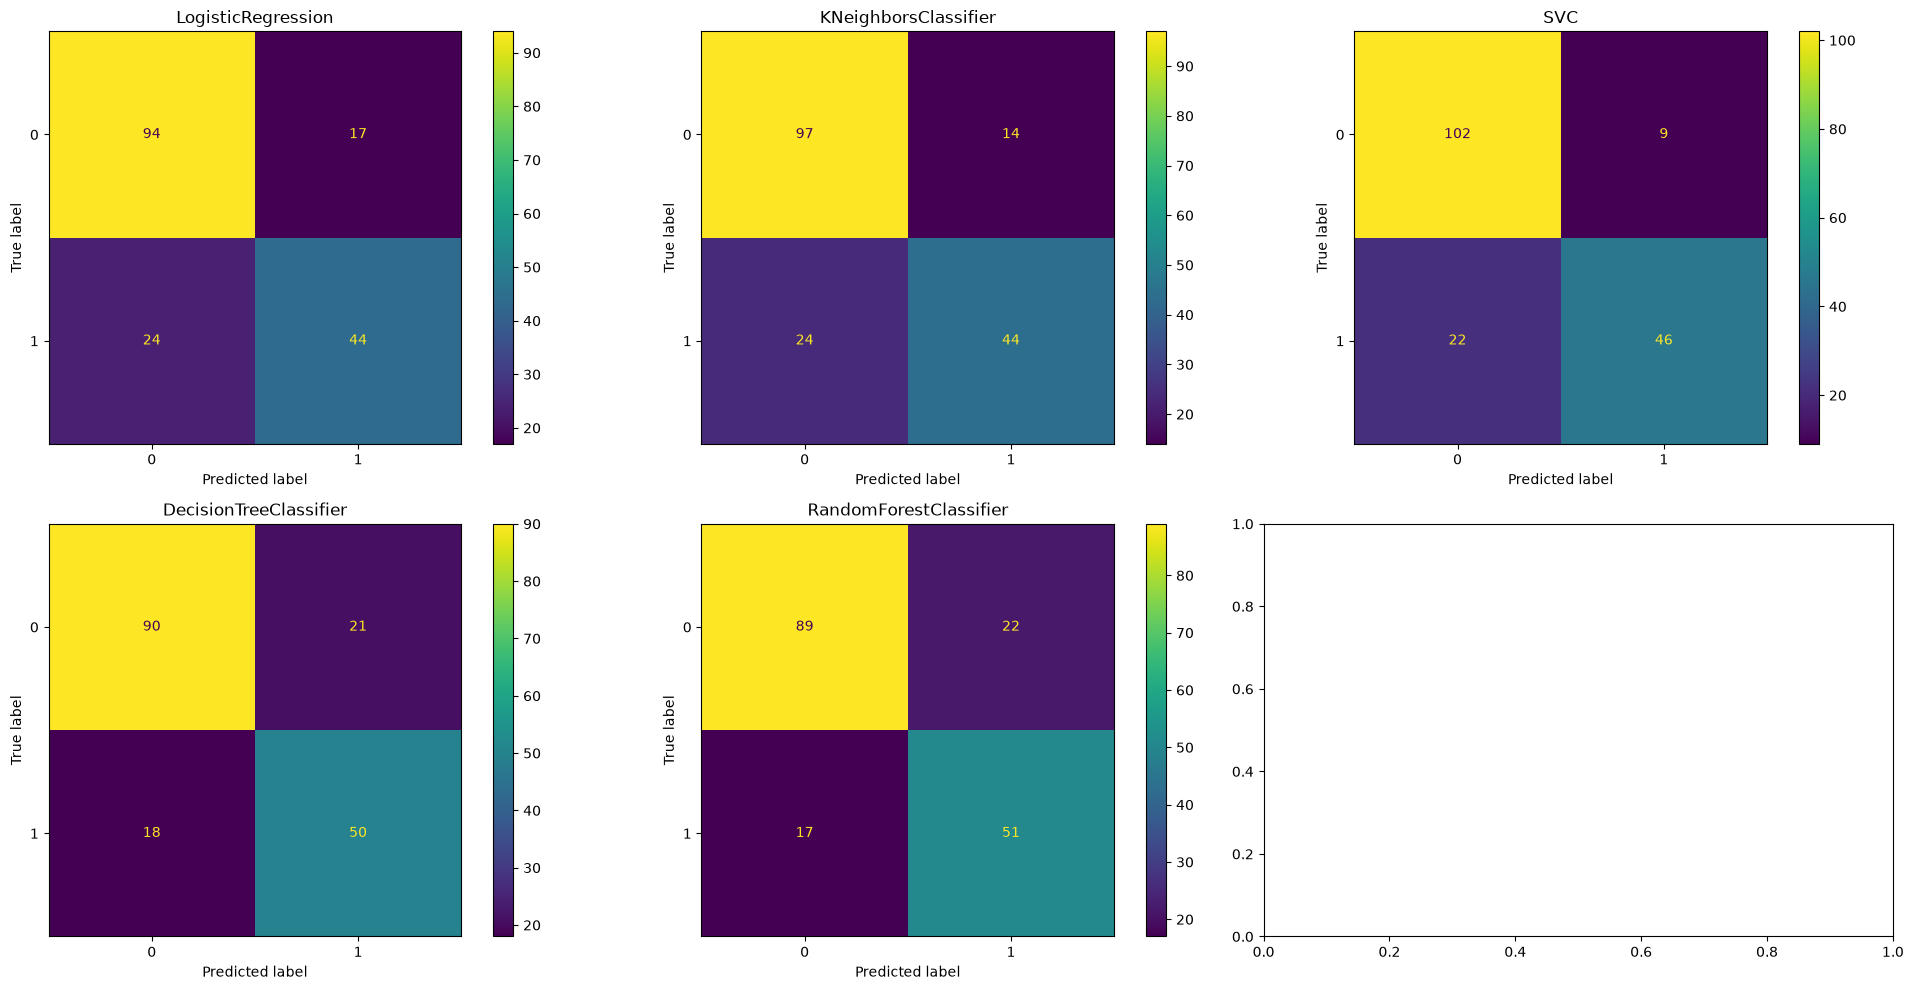

In [153]:
fig, axes = plt.subplots(nrows = 2, ncols = 3)
fig.set_figwidth(20)
fig.set_figheight(10)
ax_ = axes.flatten()

for model, ax in zip(models, ax_):
    ConfusionMatrixDisplay(cm[model]).plot(ax = ax)
    ax.set_title(str(model)[:-2])

plt.tight_layout()

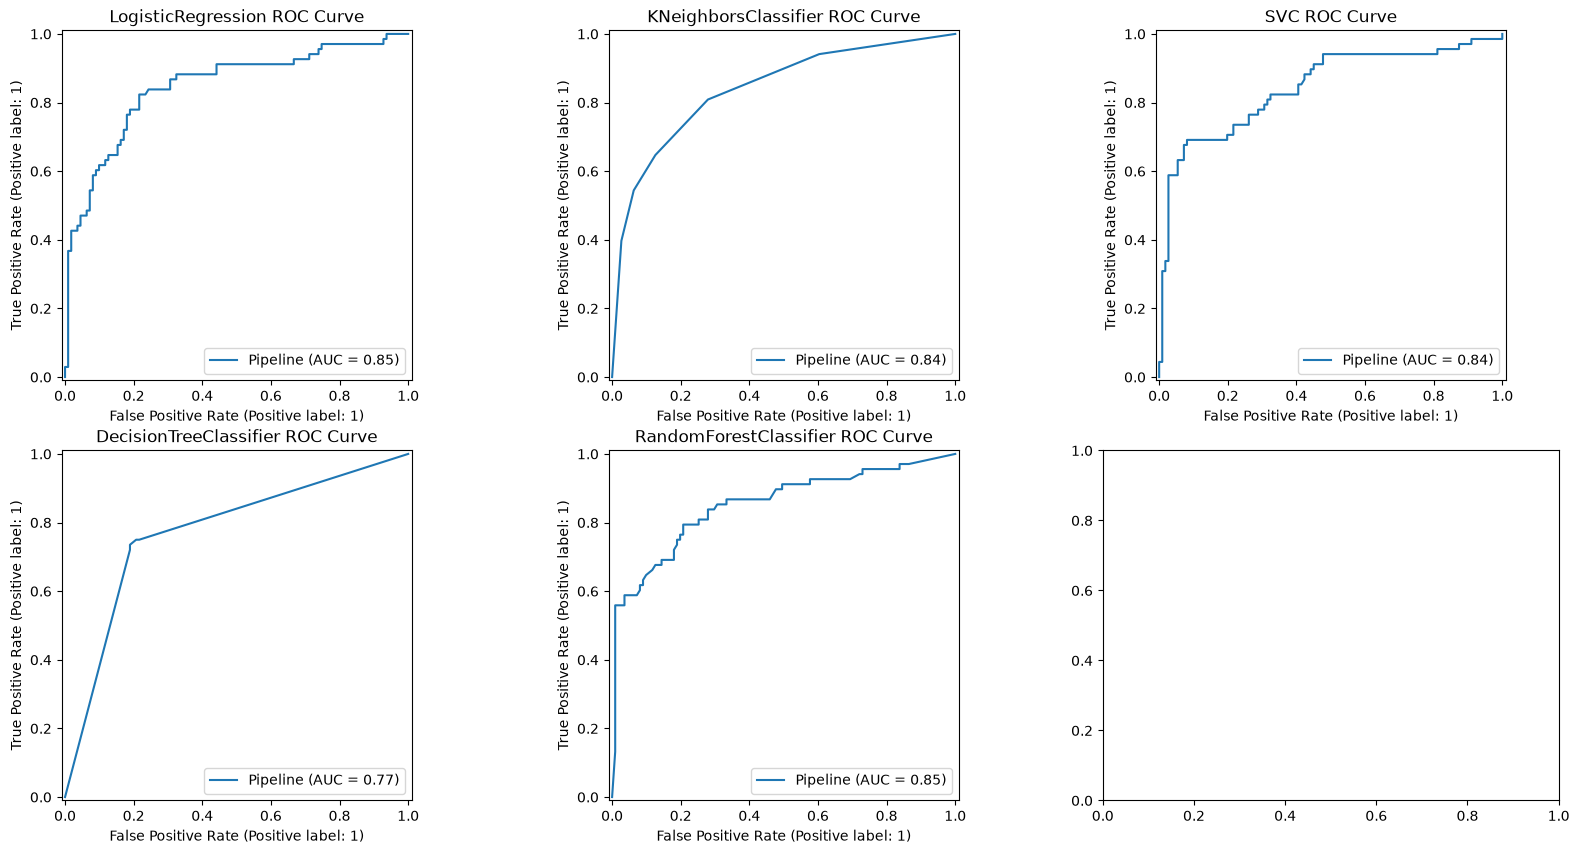

In [154]:
from sklearn.metrics import RocCurveDisplay

fig, axes = plt.subplots(nrows = 2, ncols = 3)
fig.set_figwidth(20)
fig.set_figheight(10)
ax_ = axes.flatten()

for model, ax in zip(models, ax_):
    RocCurveDisplay.from_estimator(t_models[model], X_test, y_test, ax = ax)
    ax.set_title(str(model)[:-2] + " ROC Curve")


##  Análisis

| Modelo | Accuracy | Precision (sobrevive) | Recall (sobrevive) | F1 (sobrevive) | AUC | Errores |
|---|---|---|---|---|---|---|
| **SVC** | **0,827** | **0,84** | 0,68 | **0,75** | 0,84 | **31** |
| KNN | 0,788 | 0,76 | 0,65 | 0,70 | 0,84 | 38 |
| Regresión logística | 0,771 | 0,72 | 0,65 | 0,68 | 0,85 | 41 |
| Random forest | 0,771 | 0,68 | **0,76** | 0,72 | **0,85** | 41 |
| Árbol de decisión | 0,771 | 0,68 | 0,75 | 0,71 | 0,77 | 41 |


En esta tabla a modo de resumen, vemos que SVC obtiene mejores resultados de accuracy, precision, F1, y tiene menos errores. Por otro lado, Random Fores tiene un mejor recall y AUC. Es decir, el modelo SVC predice mejor en la mayoría de los casos. Hay que tener en cuenta que  una semilla diferente podría posisionar al KNN por encima del SVC en término de errores, y otras métricas, también sería un buen modelo. 